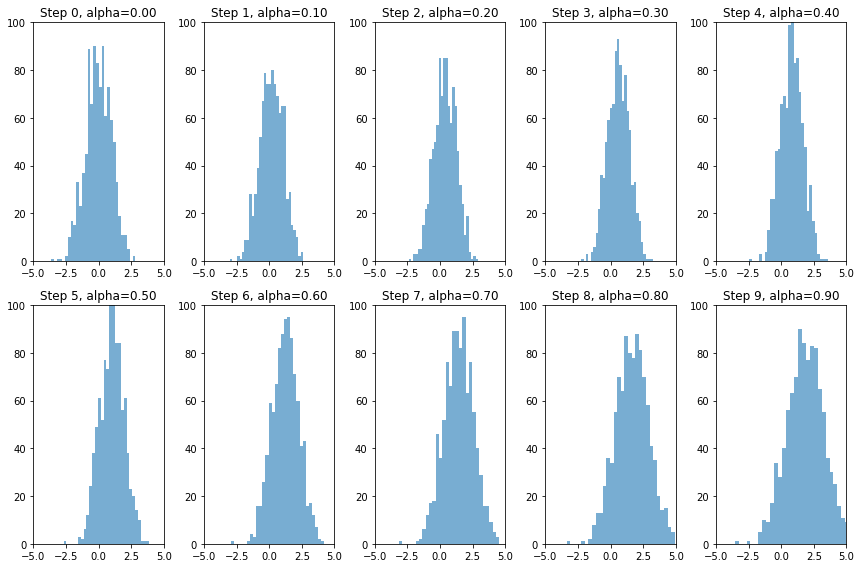

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a simple initial distribution (e.g., a Gaussian distribution)
initial_distribution = np.random.normal(loc=0.0, scale=1.0, size=1000)

# Define a target distribution (e.g., a different Gaussian distribution)
target_distribution = np.random.normal(loc=2.0, scale=1.5, size=1000)

# Function to interpolate between two distributions
def interpolate_distributions(initial, target, alpha):
    return alpha * target + (1 - alpha) * initial

# Number of steps in the stable diffusion process
steps = 10
plt.figure(figsize=(12, 8))

# Gradually transform the initial distribution into the target distribution
for i in range(steps):
    alpha = i / steps
    current_distribution = interpolate_distributions(initial_distribution, target_distribution, alpha)
    plt.subplot(2, 5, i+1)
    plt.hist(current_distribution, bins=30, alpha=0.6)
    plt.title(f'Step {i}, alpha={alpha:.2f}')
    plt.xlim([-5, 5])
    plt.ylim([0, 100])

plt.tight_layout()
plt.show()


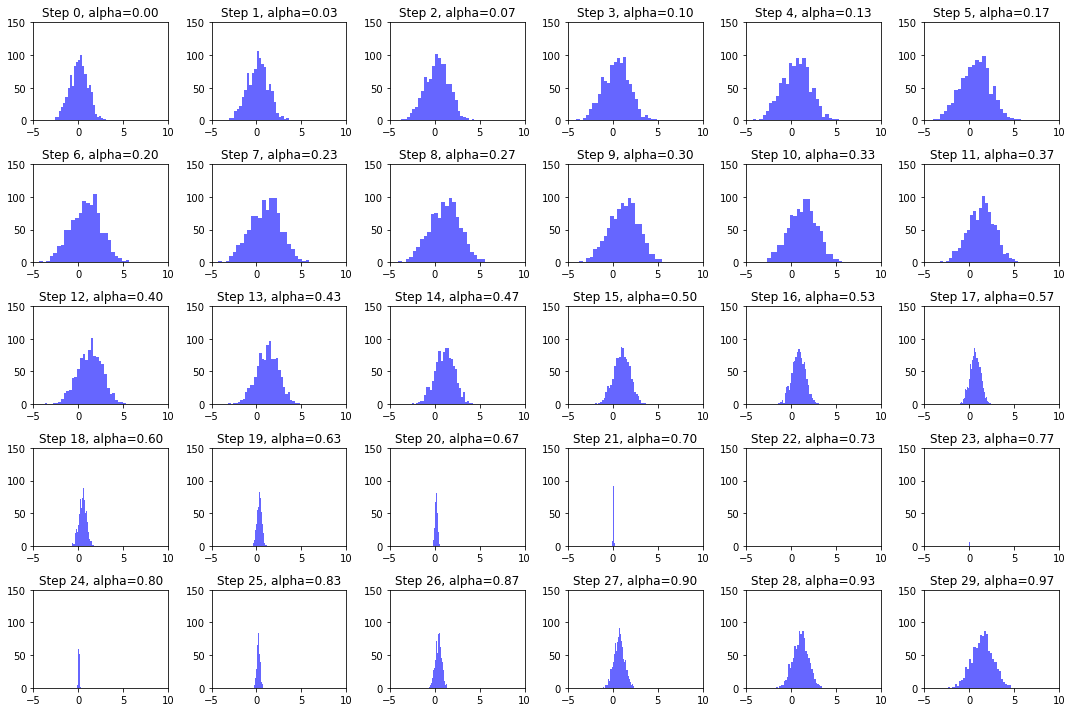

In [8]:
"""
Enhancements in this code:

    Complex Transition Function: 
    The complex_transition function now includes a dynamic scaling factor based 
    on alpha and an additional parameter beta. This factor causes the scale of 
    the distribution to change dynamically during the transition, making the process 
    more complex than a simple linear interpolation.
    Increased Steps and Visualization: The number of steps has been increased to 
    30 for a finer gradation, and the plot size has been adjusted for better visualization.
    Control Parameter beta: This parameter influences the complexity of the scaling factor. 
    Changing beta alters how the scale of the distributions changes during the transition,
    adding an additional layer of dynamics to the process.

"""

import numpy as np
import matplotlib.pyplot as plt

def complex_transition(initial, target, alpha, beta):
    """
    A more complex transition function that not only interpolates between
    initial and target distributions but also modifies the scale dynamically.
    """
    scale_factor = np.sin(beta * alpha * np.pi) + 1  # Dynamic scaling based on alpha and beta
    transition = alpha * target * scale_factor + (1 - alpha) * initial * scale_factor
    return transition

# Generate initial and target distributions
initial_distribution = np.random.normal(loc=0.0, scale=1.0, size=1000)
target_distribution = np.random.normal(loc=2.0, scale=1.5, size=1000)

steps = 30
beta = 2  # Control parameter for the complexity of the transition

plt.figure(figsize=(15, 10))

# Gradually transition from the initial to the target distribution
for i in range(steps):
    alpha = i / steps
    current_distribution = complex_transition(initial_distribution, target_distribution, alpha, beta)
    
    plt.subplot(5, 6, i + 1)
    plt.hist(current_distribution, bins=30, alpha=0.6, color='blue')
    plt.title(f'Step {i}, alpha={alpha:.2f}')
    plt.xlim([-5, 10])
    plt.ylim([0, 150])

plt.tight_layout()
plt.show()


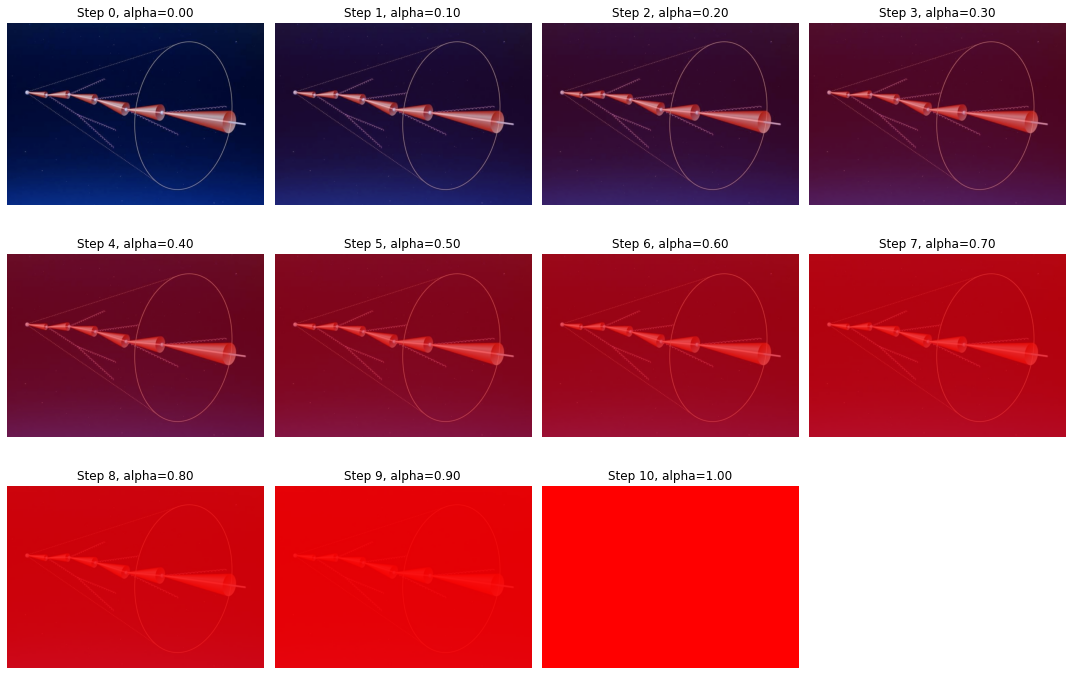

In [14]:
import matplotlib.pyplot as plt
from matplotlib.image import imread
import numpy as np
from PIL import Image

def blend_images(image1, image2, alpha):
    """
    Blend two images together using a specified alpha for transparency.
    """
    return Image.blend(image1, image2, alpha)

# Load your original image
original_img_path = 'deadcone.png'
original_img = Image.open(original_img_path)

# Ensure both images are in the same mode (convert to RGB if necessary)
if original_img.mode != 'RGB':
    original_img = original_img.convert('RGB')

# Create or load a target image to blend with (for demonstration, create a simple color image)
target_img = Image.new('RGB', original_img.size, color=(255, 0, 0))  # Red image

steps = 10
plt.figure(figsize=(15, 10))

# Gradually blend the original image with the target image
for i in range(steps + 1):
    alpha = i / steps
    blended_img = blend_images(original_img, target_img, alpha)
    
    plt.subplot(3, 4, i + 1)
    plt.imshow(blended_img)
    plt.title(f'Step {i}, alpha={alpha:.2f}')
    plt.axis('off')

plt.tight_layout()
plt.show()


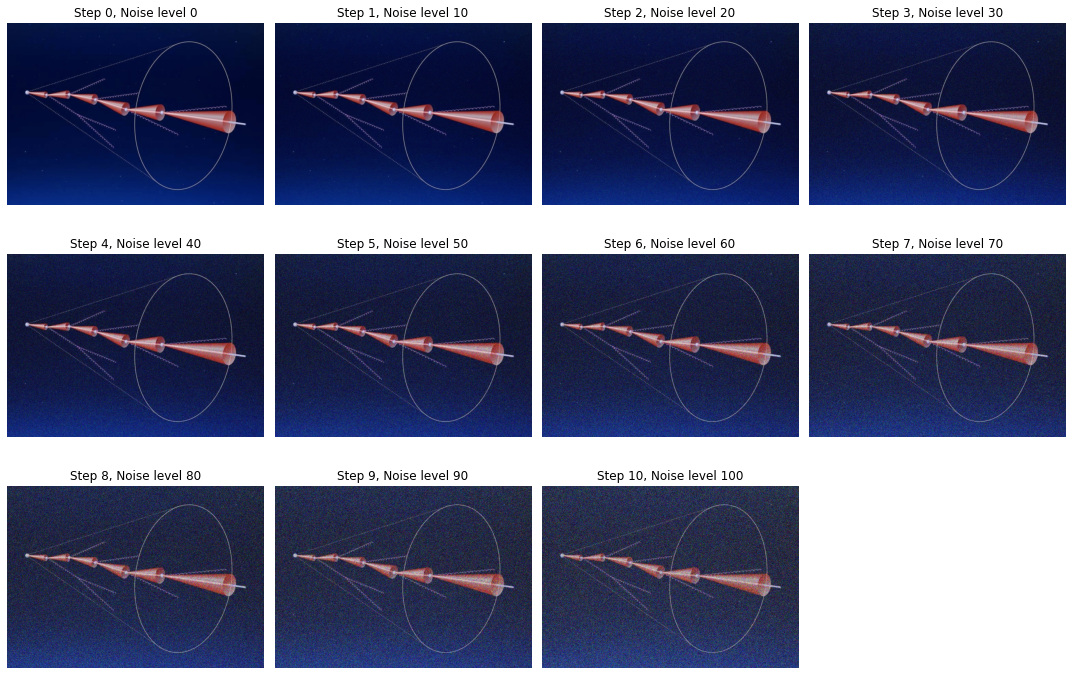

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def add_noise_to_image(image, noise_level):
    """
    Add noise to an image. The noise level determines the intensity of the noise.
    """
    # Convert image to array for manipulation
    image_array = np.array(image)
    
    # Generate noise
    noise = np.random.normal(0, noise_level, image_array.shape)

    # Add noise to image
    noisy_image = image_array + noise
    noisy_image = np.clip(noisy_image, 0, 255)  # Ensure pixel values stay in range

    # Convert back to image
    return Image.fromarray(noisy_image.astype('uint8'))

# Load your original image
original_img_path = 'deadcone.png'
original_img = Image.open(original_img_path).convert('RGB')

steps = 10
plt.figure(figsize=(15, 10))

# Gradually increase the noise level in the image
for i in range(steps + 1):
    noise_level = i * 10  # Adjust noise level as needed
    noisy_img = add_noise_to_image(original_img, noise_level)
    
    plt.subplot(3, 4, i + 1)
    plt.imshow(noisy_img)
    plt.title(f'Step {i}, Noise level {noise_level}')
    plt.axis('off')

plt.tight_layout()
plt.show()
